# NN_L1_uat_california

**Universal approximation on real data: one-hidden-layer sigmoid MLPs with 1, 3 and 50 units fitted to California house values as a function of latitude, against a straight line; held-out MSE.**

Neural Networks and Deep Learning (NN), Lecture 1 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L1/NN_L1_uat_california/NN_L1_uat_california.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

Lecture 1 of *Neural Networks and Deep Learning*: the chart `uat_california` of the slides, recomputed from the public data. Numbers printed with `show()` are the ones on the slide.

held-out MSE, H = 1 = 0.855   [uat.mse_w1]


held-out MSE, H = 3 = 0.757   [uat.mse_w3]


held-out MSE, H = 50 = 0.731   [uat.mse_w50]
held-out MSE, linear = 0.896   [uat.mse_lin]


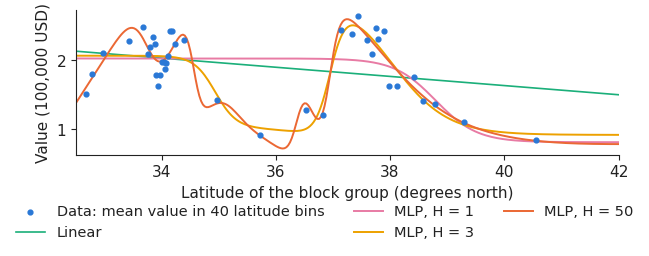

In [3]:
import xgboost as xgb            # import before torch (OpenMP runtimes on macOS)
import torch, torch.nn as nn
torch.set_num_threads(1)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss
from sklearn.model_selection import train_test_split, StratifiedKFold
SEED = 20261108

class MLP(nn.Module):
    def __init__(self, d, hidden=(64, 64), act='relu'):
        super().__init__()
        A = {'relu': nn.ReLU, 'tanh': nn.Tanh, 'sigmoid': nn.Sigmoid}[act]
        layers, k = [], d
        for h in hidden:
            layers += [nn.Linear(k, h), A()]; k = h
        layers.append(nn.Linear(k, 1)); self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x)

def train_mlp(Xtr, ytr, Xva, yva, hidden=(64, 64), act='relu', lr=1e-3, epochs=300, bs=128, patience=25, seed=0):
    """Adam on mini-batches; keeps the weights of the best validation epoch"""
    torch.manual_seed(SEED + seed); rng = np.random.default_rng(SEED + seed)
    m = MLP(Xtr.shape[1], hidden, act); opt = torch.optim.Adam(m.parameters(), lr=lr); lf = nn.BCEWithLogitsLoss()
    Xt, yt = torch.tensor(Xtr), torch.tensor(ytr, dtype=torch.float32).view(-1, 1)
    Xv, yv = torch.tensor(Xva), torch.tensor(yva, dtype=torch.float32).view(-1, 1)
    best, state, bad = np.inf, None, 0
    for ep in range(epochs):
        m.train(); idx = rng.permutation(len(Xt))
        for i in range(0, len(idx), bs):
            b = idx[i:i + bs]; opt.zero_grad(); lf(m(Xt[b]), yt[b]).backward(); opt.step()
        m.eval()
        with torch.no_grad():
            vl = float(lf(m(Xv), yv))
        if vl < best - 1e-5:
            best, bad, state = vl, 0, {k: v.clone() for k, v in m.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                break
    m.load_state_dict(state); m.eval()
    return m

def proba(m, X):
    with torch.no_grad():
        return torch.sigmoid(m(torch.tensor(X))).numpy().ravel()

def xgb_fit(Xtr, ytr, Xva, yva, seed=0):
    m = xgb.XGBClassifier(n_estimators=600, learning_rate=0.03, max_depth=4, subsample=0.8, colsample_bytree=0.8,
                          eval_metric='logloss', early_stopping_rounds=50, random_state=SEED + seed, n_jobs=1)
    m.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
    return m
ca = pd.read_csv(DATA + 'california_housing.csv')
x1, y1 = ca['Latitude'].values.astype(np.float32), ca['MedHouseVal_100k_usd'].values.astype(np.float32)
keep = y1 < 5.0; x1, y1 = x1[keep], y1[keep]
a, b = train_test_split(np.arange(len(x1)), test_size=0.25, random_state=SEED); mx, sx = x1[a].mean(), x1[a].std()
xs = np.linspace(32.5, 42, 300).astype(np.float32); fits = {}
for H in (1, 3, 50):
    torch.manual_seed(SEED + H); m = MLP(1, (H,), 'sigmoid'); opt = torch.optim.Adam(m.parameters(), lr=0.02)
    Xa, Ya = torch.tensor((x1[a, None] - mx) / sx), torch.tensor(y1[a, None])
    for it in range(4000):
        opt.zero_grad(); nn.MSELoss()(m(Xa), Ya).backward(); opt.step()
    with torch.no_grad():
        fits[H] = m(torch.tensor((xs[:, None] - mx) / sx)).numpy().ravel()
        show(f'uat.mse_w{H}', f'held-out MSE, H = {H}', round(float(nn.MSELoss()(m(torch.tensor((x1[b, None] - mx) / sx)), torch.tensor(y1[b, None]))), 3))
bl = np.polyfit(x1[a], y1[a], 1); show('uat.mse_lin', 'held-out MSE, linear', round(float(np.mean((np.polyval(bl, x1[b]) - y1[b]) ** 2)), 3))
bins = np.quantile(x1[a], np.linspace(0, 1, 41)); bc = np.digitize(x1[a], bins[1:-1])
fig, ax = plt.subplots(figsize=(6.4, 2.6))
ax.scatter([x1[a][bc == k].mean() for k in range(40)], [y1[a][bc == k].mean() for k in range(40)], s=12, color=PAL['data'], zorder=3,
           label='Data: mean value in 40 latitude bins')
ax.plot(xs, np.polyval(bl, xs), color=PAL['benchmark'], lw=1.2, label='Linear')
for H, c in ((1, '#e87ba4'), (3, PAL['alt']), (50, PAL['model'])):
    ax.plot(xs, fits[H], color=c, lw=1.4, label=f'MLP, H = {H}')
ax.set_xlabel('Latitude of the block group (degrees north)'); ax.set_ylabel('Value (100,000 USD)'); ax.set_xlim(32.5, 42)
legend_bottom(fig, ncol=3); fig.tight_layout(rect=(0, 0.14, 1, 1))
fig.savefig('uat_california.png', dpi=200, transparent=True, bbox_inches='tight'); plt.show()